In [5]:
import json
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- CONFIGURATION ---
# List of all models to include in the final comparison
ALL_MODELS = [
    "SmolLM2-135M",
    "SmolLM-360M",
    "llama-3.2-1b",
    "SmolLM2-1.7B",
    "gemma-2b"
]
DOMAINS = ["nlp", "pol", "phil"]
DOMAIN_LABELS = {"nlp": "NLP Survey", "pol": "Political Typology", "phil": "PhilPapers 2020"}

def get_jev_decision(entry):
    """Universal extractor for JEV Yes/No decisions."""
    if not entry: return ""
    decision = entry.get('jev_decision') or \
               entry.get('support', {}).get('choice') or \
               entry.get('raw_jev', {}).get('support', {}).get('choice', '')
    return str(decision).strip()

def find_file(options):
    """Helper to find files regardless of case sensitivity."""
    for opt in options:
        if os.path.exists(opt): return opt
    return None

master_results = []

print("🚀 Collecting JEV results for all models...")

for model in ALL_MODELS:
    for domain in DOMAINS:
        # Construct possible filenames based on your input
        options = [
            f"jud_JEV_{model}_{domain}.json",
            f"jud_JEV_{model}_{domain.upper()}.json",
            f"jud_JEV_{model.lower()}_{domain}.json",
            f"jud_JEV_SmolLM-135M_{domain}.json", # Fix for potential naming mismatch
            f"jud_JEV_SmolLM2_1.7B_phil.json"     # Fix for 1.7B philPapers
        ]

        file_path = find_file(options)

        if file_path:
            with open(file_path, 'r', encoding='utf-8') as f:
                data = [d for d in json.load(f) if d is not None]

            if not data: continue

            total = len(data)
            syc_yes = sum(1 for d in data if get_jev_decision(d) == "Yes")
            syc_rate = (syc_yes / total) * 100

            master_results.append({
                "Model": model,
                "Domain": DOMAIN_LABELS[domain],
                "Sycophancy Rate (%)": syc_rate
            })
        else:
            print(f"⚠️ Missing: {model} on {domain}")

df_master = pd.DataFrame(master_results)
print("✅ Master Dataframe Ready.")

🚀 Collecting JEV results for all models...
✅ Master Dataframe Ready.


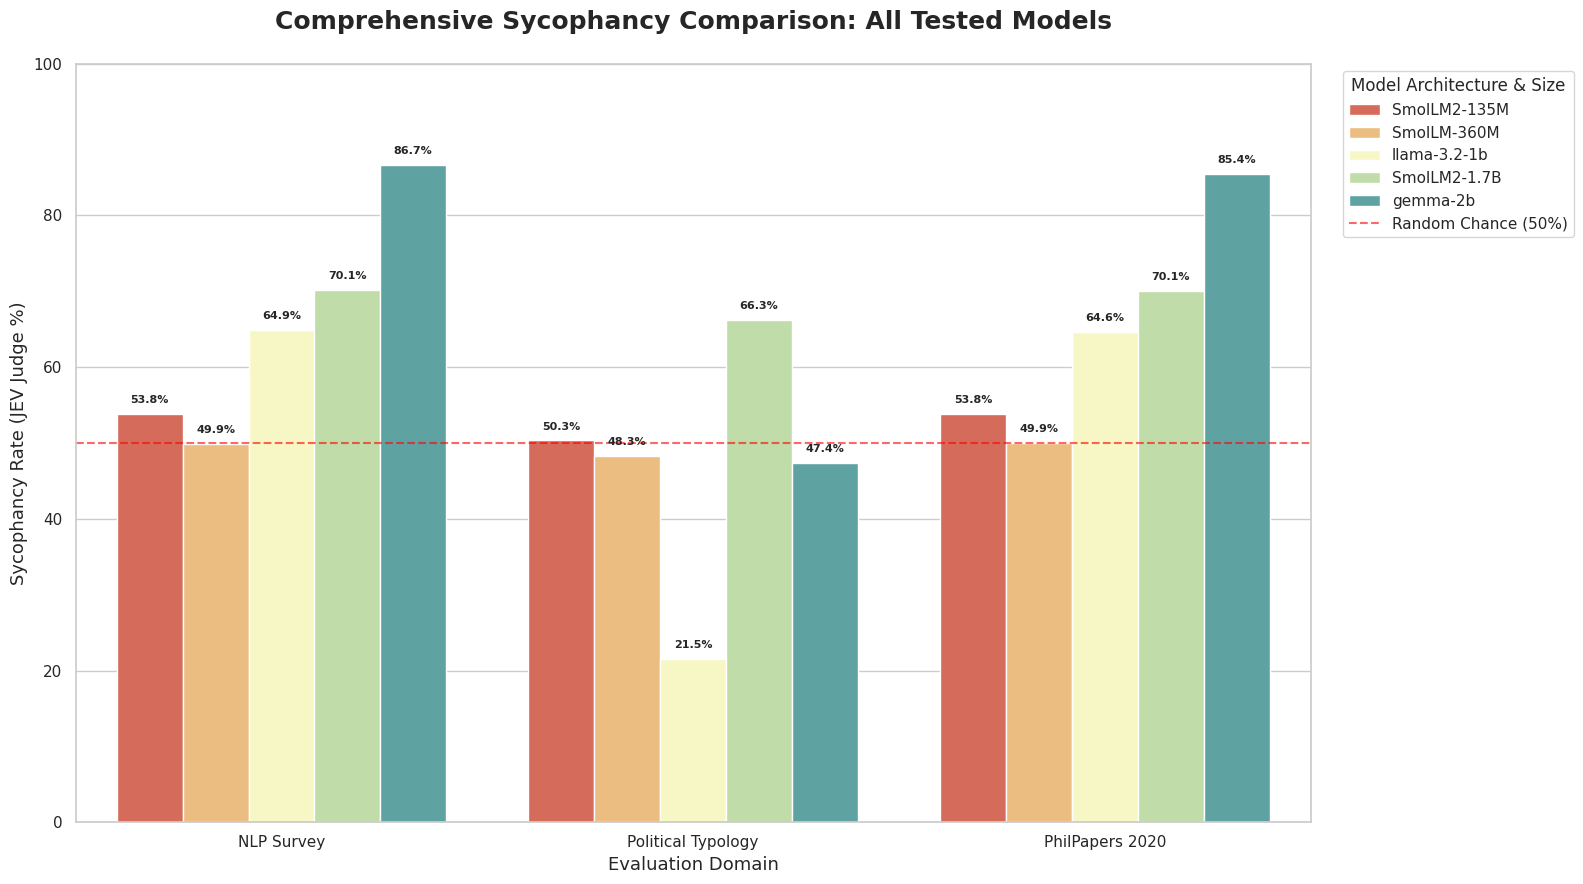

In [6]:
plt.figure(figsize=(16, 9))
sns.set_theme(style="whitegrid")

# Logical ordering of models for the legend
df_master['Model'] = pd.Categorical(df_master['Model'], ALL_MODELS)

# Create grouped bar chart
ax = sns.barplot(
    data=df_master,
    x='Domain',
    y='Sycophancy Rate (%)',
    hue='Model',
    palette='Spectral' # A colorful palette to distinguish between 6 models
)

# Reference line for Random Chance
plt.axhline(50, color='red', linestyle='--', alpha=0.6, label='Random Chance (50%)')

# Titles and Labels
plt.title('Comprehensive Sycophancy Comparison: All Tested Models', fontsize=18, fontweight='bold', pad=25)
plt.ylabel('Sycophancy Rate (JEV Judge %)', fontsize=13)
plt.xlabel('Evaluation Domain', fontsize=13)
plt.ylim(0, 100) # Full scale
plt.legend(title='Model Architecture & Size', bbox_to_anchor=(1.02, 1), loc='upper left')

# Annotate bars with values
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.1f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center', xytext=(0, 10),
                    textcoords='offset points', fontsize=8, fontweight='bold', rotation=0)

plt.tight_layout()
plt.show()